In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import warnings
#warnings.simplefilter("ignore")
%matplotlib inline

sns.set_theme(style="darkgrid")

In [ ]:
url_red = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
url_white = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"

df_red = pd.read_csv(url_red, sep=';')
df_red['color'] = 0  # 0 — красное вино

df_white = pd.read_csv(url_white, sep=';')
df_white['color'] = 1  # 1 — белое вино

# Объединяем в один датасет
df = pd.concat([df_red, df_white], ignore_index=True)

print("Общий размер объединенного датасета:", df.shape)
display(df.head())
df.info()

Общий размер объединенного датасета: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0


<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  color                 6497 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 660.0 KB


C:\Users\mrkir\AppData\Local\Temp\ipykernel_3608\2914710794.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='quality', palette='viridis')


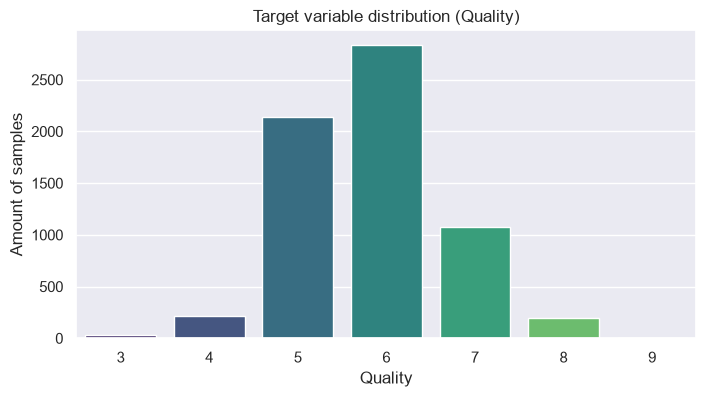

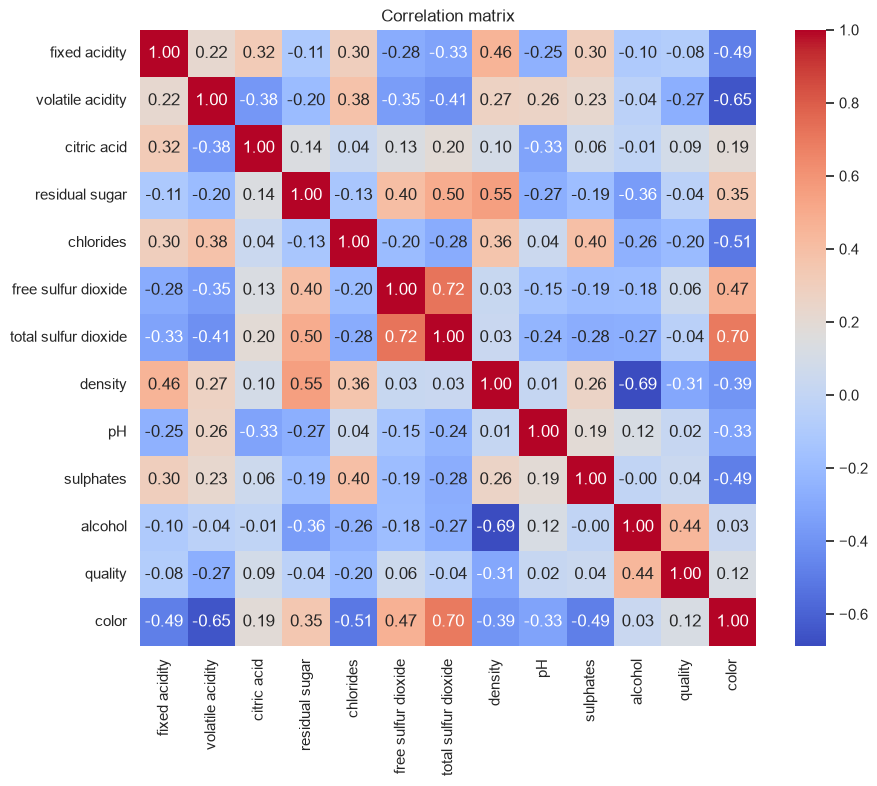

In [ ]:
# Распределение целевой переменной (quality)
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='quality', palette='viridis')
plt.title('Target variable distribution (Quality)')
plt.xlabel('Quality')
plt.ylabel('Amount of samples')
plt.show()

# Матрица корреляций
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', square=True)
plt.title('Correlation matrix')
plt.show()

### Выводы по EDA

**1. Структура данных.** 6497 вин (1599 красных, 4898 белых). Тип вина — в признаке `color` (0 — красное, 1 — белое).

**2. Целевая переменная (`quality`).** Оценки от 3 до 9, но 76.6% вин имеют 5 или 6, а оценки 3 и 9 крайне редки (30 и 5 штук). Среднее ≈ 5.82, std ≈ 0.87. Следствие: модели будут «тяготеть» к середине и хуже работать на редких оценках. Константа «среднее» уже даёт RMSE ≈ 0.86, поэтому порог 0.70 требует снизить ошибку лишь на ~19%.

**3. Красные и белые вина — разные популяции.** Белые в среднем выше по качеству (5.88 против 5.64) и по содержанию SO₂ и сахара; у красных вдвое выше летучая кислотность. Значит, `color` важен, и закономерности могут различаться по типам.

**4. Связь признаков с качеством.** Сильнее всего коррелируют `alcohol` (+0.44), `density` (−0.31), `volatile acidity` (−0.27), `chlorides` (−0.20). Остальные — |r| < 0.1. Ни один признак в одиночку не объясняет качество (максимум r² ≈ 0.2), нужна комбинация. Слабую корреляцию не повод выкидывать признак — возможны нелинейные эффекты.

**5. Мультиколлинеарность.** Связаны: `free` и `total sulfur dioxide` (0.72), `density` и `alcohol` (−0.69), `density` и `residual sugar` (0.55), `color` с SO₂, кислотностью и хлоридами. Следствие: коэффициенты линейной регрессии нестабильны и плохо интерпретируемы; на деревья это почти не влияет.

**6. Масштабы и распределения.** Признаки в разных масштабах, поэтому для линейной регрессии нужно масштабирование, иначе коэффициенты несравнимы. Многие признаки скошены вправо и имеют выбросы; линейная модель к ним чувствительна, деревья — нет, им масштабирование не нужно.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

# Выделяем признаки (X) и целевую переменную (y)
X = df.drop(columns=['quality'])
y = df['quality']

# Разбиваем на Train (80%) и Test (20%)
# Выбор 80/20 — стандартный баланс между достаточностью данных для обучения и надежностью теста.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Размер обучающей выборки: {X_train.shape[0]} объектов")
print(f"Размер тестовой выборки: {X_test.shape[0]} объектов")

# Строим Baseline (предсказание средним значением y_train)
baseline_pred = np.full_like(y_test, fill_value=y_train.mean(), dtype=float)

# Расчет метрик для Baseline
baseline_rmse = root_mean_squared_error(y_test, baseline_pred)
baseline_mae = mean_absolute_error(y_test, baseline_pred)

# Создаем итоговую таблицу результатов
results_df = pd.DataFrame({
    'Model': ['Baseline (Mean)'],
    'RMSE': [baseline_rmse],
    'MAE': [baseline_mae]
})

display(results_df)

Размер обучающей выборки: 5197 объектов
Размер тестовой выборки: 1300 объектов


,Model,RMSE,MAE
0,Baseline (Mean),0.859605,0.669097


### Подготовка выборок и baseline

**1. Размер выборок.** Разбиение 80/20. Этого достаточно и для обучения, и для устойчивой оценки RMSE.

**2. Способ разбиения.** Случайное `train_test_split` с `random_state=42` — воспроизводимо, допустимо, т.к. данные не упорядочены и не сгруппированы. Стратификацию не применяли, так что доли оценок в train и test чуть различаются — ещё одна причина не доверять разнице в сотых. Из-за 18% дубликатов ~27.6% теста имеют копию в train: это завышает оценку «запоминающих» моделей (особенно Random Forest).

**3. Проблема многократной оценки на тесте.** Если выбирать модель по результатам на тесте, тест перестаёт быть независимым (утечка при выборе модели), и итоговая метрика завышается. Поэтому тест используем один раз — для финальной оценки.

**4. Baseline.** Предсказание константой. Для RMSE оптимально среднее (минимизирует сумму квадратов), для MAE — медиана. Берём среднее по train (≈ 5.82; по test брать нельзя — утечка). Baseline: **RMSE = 0.860, MAE = 0.669**. Если модель не опускается заметно ниже 0.86 — она ничего не выучила.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

# Масштабирование признаков
scaler = StandardScaler()

# Обучаем scaler только на train и трансформируем train
X_train_scaled = scaler.fit_transform(X_train)

# К test применяем только transform!
X_test_scaled = scaler.transform(X_test)

# Обучение модели Линейной Регрессии
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

# Предсказание на тестовой выборке
lr_pred = lr_model.predict(X_test_scaled)

# Расчет метрик
lr_rmse = root_mean_squared_error(y_test, lr_pred)
lr_mae = mean_absolute_error(y_test, lr_pred)

# Добавляем результат в общую таблицу
new_row = pd.DataFrame({'Model': ['Linear Regression'], 'RMSE': [lr_rmse], 'MAE': [lr_mae]})
results_df = pd.concat([results_df, new_row], ignore_index=True)

display(results_df)

,Model,RMSE,MAE
0,Baseline (Mean),0.859605,0.669097
1,Linear Regression,0.735689,0.564413


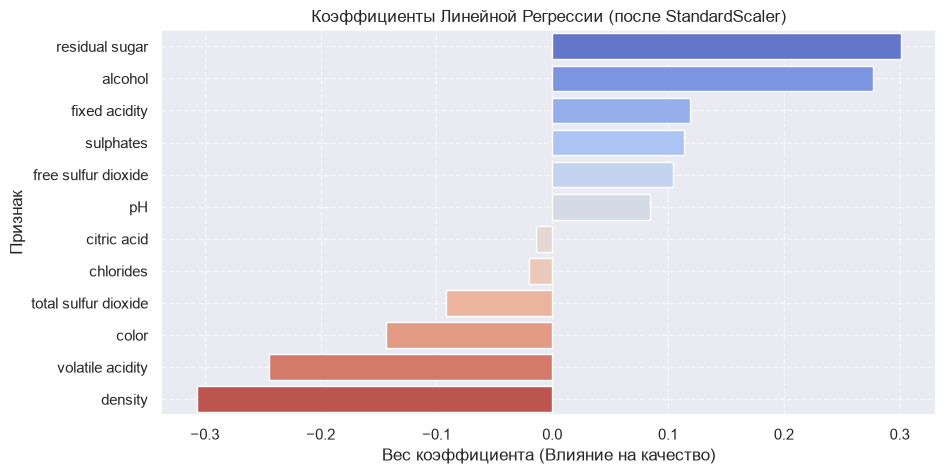

Топ положительных признаков (повышают оценку качества):


,Feature,Coefficient
3,residual sugar,0.301300
10,alcohol,0.277079
0,fixed acidity,0.118681


Топ отрицательных признаков (понижают оценку качества):


,Feature,Coefficient
11,color,-0.143580
1,volatile acidity,-0.244675
7,density,-0.307099


In [17]:
# Создаем DataFrame с коэффициентами
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lr_model.coef_
}).sort_values(by='Coefficient', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(data=coef_df, x='Coefficient', y='Feature', hue='Feature', palette='coolwarm', legend=False)
plt.title('Коэффициенты Линейной Регрессии (после StandardScaler)')
plt.xlabel('Вес коэффициента (Влияние на качество)')
plt.ylabel('Признак')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

print("Топ положительных признаков (повышают оценку качества):")
display(coef_df.head(3))

print("Топ отрицательных признаков (понижают оценку качества):")
display(coef_df.tail(3))

### Анализ линейной регрессии

**Качество.** RMSE = **0.736**, MAE = 0.564. Лучше baseline на 14%, но порог 0.70 не пройден.

**Масштабирование.** Нужно для *интерпретации* коэффициентов: без него они несопоставимы (у `density` −102, у `alcohol` +0.23), т.к. зависят от масштаба признака. После `StandardScaler` коэффициент = изменение прогноза при росте признака на 1 std. На сами предсказания линейной регрессии масштабирование не влияет.

**Сильнейшие признаки** (по |коэффициенту|): `density` (−0.31), `residual sugar` (+0.30), `alcohol` (+0.28), `volatile acidity` (−0.24), `color` (−0.14). Слабейшие: `chlorides`, `citric acid`.

**Осторожно с интерпретацией:**
* `density` и `residual sugar` в топе из-за мультиколлинеарности: плотность — почти функция алкоголя и сахара, и их коэффициенты (+0.30 и −0.31) взаимно компенсируются. Это артефакт, а не доказательство, что сахар повышает качество.
* `color` имеет отрицательный коэффициент, хотя белые вина в среднем оцениваются выше — знак при коррелированных признаках может не совпадать с парной корреляцией.
* Устойчиво выделяются только `alcohol` (+) и `volatile acidity` (−) — они подтверждены и корреляциями, и деревьями.

In [ ]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Обучение Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)  # Для деревьев используем исходный X_train

rf_pred = rf_model.predict(X_test)

rf_rmse = root_mean_squared_error(y_test, rf_pred)
rf_mae = mean_absolute_error(y_test, rf_pred)

# Обучение Gradient Boosting Regressor
gb_model = GradientBoostingRegressor(n_estimators=100, random_state=42)
gb_model.fit(X_train, y_train)

gb_pred = gb_model.predict(X_test)

gb_rmse = root_mean_squared_error(y_test, gb_pred)
gb_mae = mean_absolute_error(y_test, gb_pred)

# Обновляем итоговую таблицу результатов
models_data = pd.DataFrame({
    'Model': ['Random Forest', 'Gradient Boosting'],
    'RMSE': [rf_rmse, gb_rmse],
    'MAE': [rf_mae, gb_mae]
})

results_df = pd.concat([results_df, models_data], ignore_index=True)
display(results_df)

,Model,RMSE,MAE
0,Baseline (Mean),0.859605,0.669097
1,Linear Regression,0.735689,0.564413
2,Random Forest,0.608227,0.436754
3,Gradient Boosting,0.678413,0.532242


### Сравнение моделей

| Модель | RMSE | MAE | < 0.70? |
|---|---|---|---|
| Baseline (среднее train) | 0.860 | 0.669 | нет |
| Linear Regression | 0.736 | 0.564 | **нет** |
| Random Forest | **0.608** | **0.437** | да |
| Gradient Boosting | 0.678 | 0.532 | да |

* Baseline превзошли все модели (улучшение RMSE на 14–29%), значит признаки полезны. Порог 0.70 прошли только деревья.
* **Лучшая — Random Forest** (RMSE 0.608). RMSE/MAE ≈ 1.39 — есть небольшое число крупных промахов.
* **Почему деревья лучше линейной модели.** Они ловят нелинейности и взаимодействия, не боятся масштабов, выбросов и мультиколлинеарности. Часть преимущества RF — из-за дубликатов: без них RMSE леса растёт до 0.664, а у линейной регрессии остаётся 0.721.
* **Почему RF лучше GB.** При параметрах по умолчанию бустинг с мелкими деревьями (глубина 3) недообучен (train 0.635, test 0.678), а лес строит глубокие деревья и усредняет их. При подборе гиперпараметров GB, вероятно, сократил бы отставание — это тема следующих занятий. Вывод «RF лучше GB» относится именно к конфигурациям по умолчанию.
* **Переобучение.** У RF сильный разрыв train/test (0.227 / 0.608) — это нормально для леса, честная оценка — тестовая (0.608). У линейной регрессии разрыва нет (0.732 / 0.736).

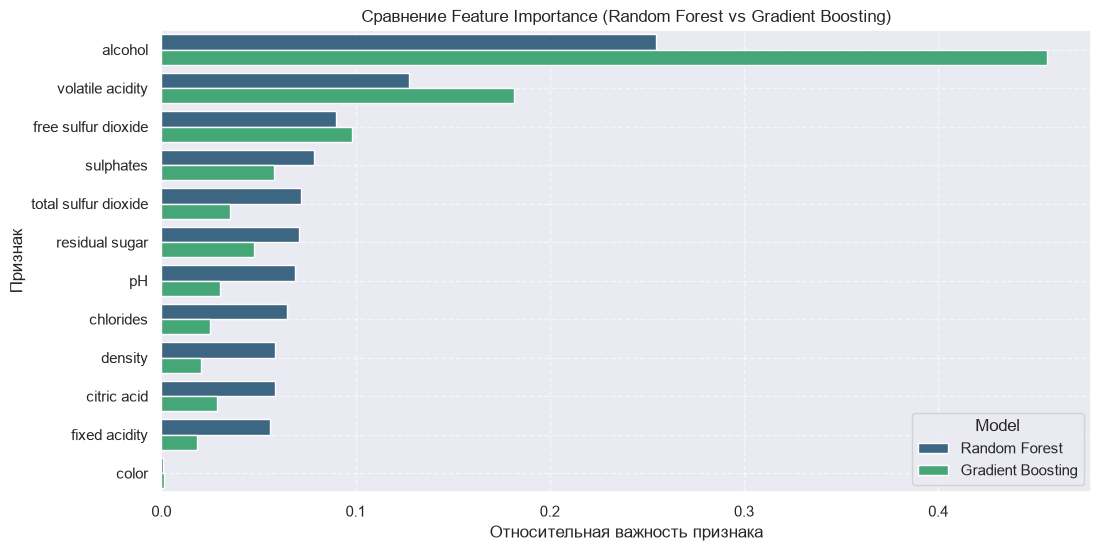

,Feature,Random Forest,Gradient Boosting
10,alcohol,0.254585,0.456073
1,volatile acidity,0.127507,0.181419
5,free sulfur dioxide,0.089717,0.098402
9,sulphates,0.078344,0.057764
6,total sulfur dioxide,0.071939,0.035221
3,residual sugar,0.070934,0.047441
8,pH,0.068788,0.030099
4,chlorides,0.064446,0.024833
7,density,0.058684,0.020361
2,citric acid,0.058301,0.028602


In [15]:
# Создаем DataFrame с важностью признаков
fi_df = pd.DataFrame({
    'Feature': X.columns,
    'Random Forest': rf_model.feature_importances_,
    'Gradient Boosting': gb_model.feature_importances_
}).sort_values(by='Random Forest', ascending=False)

# Визуализация сравнения важностей
plt.figure(figsize=(12, 6))
fi_melted = pd.melt(fi_df, id_vars=['Feature'], var_name='Model', value_name='Importance')

sns.barplot(data=fi_melted, x='Importance', y='Feature', hue='Model', palette='viridis')
plt.title('Сравнение Feature Importance (Random Forest vs Gradient Boosting)')
plt.xlabel('Относительная важность признака')
plt.ylabel('Признак')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

display(fi_df)

### Анализ важности признаков

**1. Лидеры.** В обеих моделях лидируют **`alcohol`** (RF 25%, GB 46%) и **`volatile acidity`** (13% и 18%). Далее `free sulfur dioxide`, `sulphates`, `total sulfur dioxide`, `residual sugar`. Признак `color` почти не важен (<0.2%): деревья «видят» тип вина по SO₂, кислотности и хлоридам.

**2. Сопоставление с EDA.** Верх согласуется с корреляциями (`alcohol` +0.44, `volatile acidity` −0.27). Но `density` и `chlorides` с заметной корреляцией — внизу списка: их информация покрывается другими признаками (плотность — функция алкоголя и сахара). А `free sulfur dioxide` со слабой корреляцией важен для деревьев — вероятно, эффект нелинейный.

**3. Сопоставление с линейной регрессией.** Совпадает только верхушка (`alcohol`, `volatile acidity`). В линейной модели на первых местах `density` и `residual sugar`, а в деревьях они ниже: из-за мультиколлинеарности линейная модель «делит» вклад между зависимыми признаками произвольно, поэтому порядок признаков по важности в деревьях надёжнее.

**4. RF vs GB.** Порядок признаков почти совпадает. Разница в концентрации: бустинг сильнее опирается на `alcohol` (46% против 25%) и почти игнорирует слабые признаки, лес распределяет важность равномернее (выбирает из случайного подмножества). Также `feature_importances_` деревьев завышает важность признаков с большим числом уникальных значений.

**5. Можно ли говорить о причинности?** **Нет.** Feature importance показывает полезность для предсказания, а не причинный эффект. Причины: данные наблюдательные (алкоголь может быть индикатором сорта/региона/цены); коррелированные признаки делят важность произвольно; важность не даёт ни направления, ни формы эффекта и зависит от модели и выборки; оценка дегустаторов субъективна. Для причинности нужен контролируемый эксперимент или методы причинного вывода.

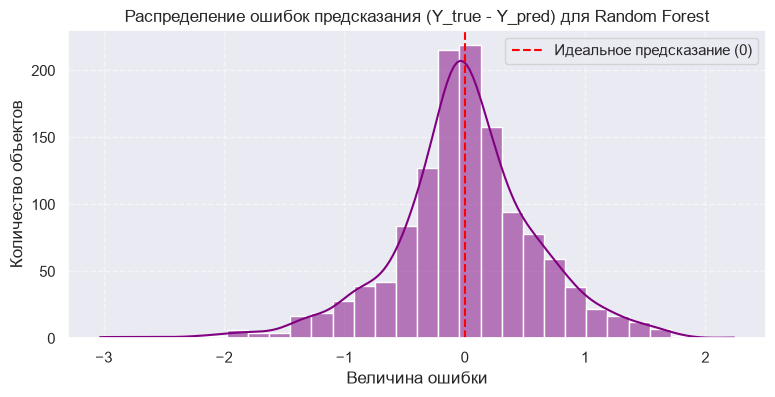

Топ-5 объектов с самыми грубыми ошибками модели:


,True_Quality,Predicted_Quality,Absolute_Error
2339,3,6.03,3.03
6344,3,5.91,2.91
3649,3,5.63,2.63
3016,3,5.55,2.55
3715,4,6.26,2.26


In [ ]:
# Считаем ошибки для лучшей модели (Random Forest)
rf_errors = y_test - rf_pred  # Истинное минус предсказанное

# Строим распределение ошибок
plt.figure(figsize=(9, 4))
sns.histplot(rf_errors, kde=True, color='purple', bins=30)
plt.title('Распределение ошибок предсказания (Y_true - Y_pred) для Random Forest')
plt.xlabel('Величина ошибки')
plt.ylabel('Количество объектов')
plt.axvline(0, color='red', linestyle='--', label='Идеальное предсказание (0)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Находим объекты с самыми крупными (абсолютными) ошибками
error_df = pd.DataFrame({
    'True_Quality': y_test,
    'Predicted_Quality': rf_pred,
    'Absolute_Error': np.abs(rf_errors)
}).sort_values(by='Absolute_Error', ascending=False)

print("Топ-5 объектов с самыми грубыми ошибками модели:")
display(error_df.head(5))

### Анализ ошибок Random Forest

1. **Распределение ошибок.** Разница $Y_{true} - Y_{pred}$ близка к нормальной и симметрична относительно нуля — систематического смещения нет (модель не занижает и не завышает постоянно).

2. **Крупные ошибки на крайних значениях (3, 4, 8).** Главная причина — **дисбаланс оценок**: подавляющее большинство вин имеют 5 или 6, и модель «осторожничает» на редких классах, не решаясь давать крайние прогнозы.

3. **Специфика задачи.** Оценки ставят дегустаторы субъективно; часть нюансов невозможно зафиксировать 11 химическими признаками. Это накладывает естественный предел точности любых алгоритмов на этих данных.